In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df = pd.read_csv("cleaned_corpus.csv", index_col = 0, parse_dates = ['approved_date'])
corpus = df['cleaned_content']

[Text(0.5, 1.0, 'RAs per year'), Text(0.5, 0, 'Year'), Text(0, 0.5, 'Count')]

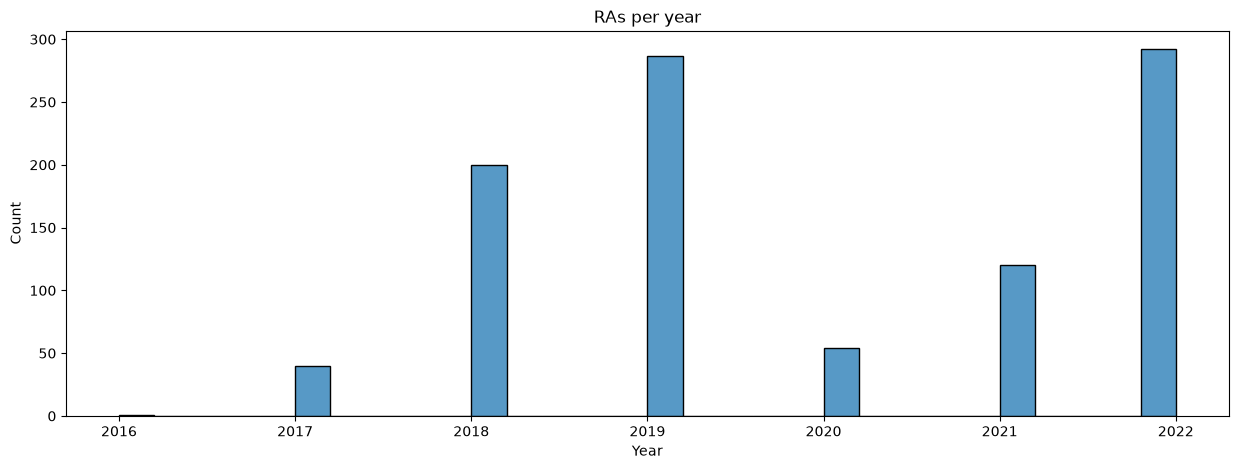

In [12]:
fig, ax = plt.subplots(figsize = (15, 5))
g = sns.histplot(x = 'year', bins = 30, data = df, ax = ax)
g.set(title = 'RAs per year', xlabel = 'Year', ylabel = 'Count')

In [13]:
count_vectorizer = CountVectorizer()
vectorized = count_vectorizer.fit_transform(corpus)

print("Shape of our DTM:", vectorized.shape)

Shape of our DTM: (994, 14816)


In [15]:
dtm = pd.DataFrame(
    vectorized.toarray(),
    columns = count_vectorizer.get_feature_names_out(),
    index = df['basename']
)

In [16]:
def plot_metrics(data, col, title = '', xlabel = ''):
    """Plot metrics with a histogram."""
    fig, ax = plt.subplots(figsize = (15, 5))
    g = sns.histplot(x = col, data = data)
    g.set(title = title, xlabel = xlabel, ylabel = 'Count')

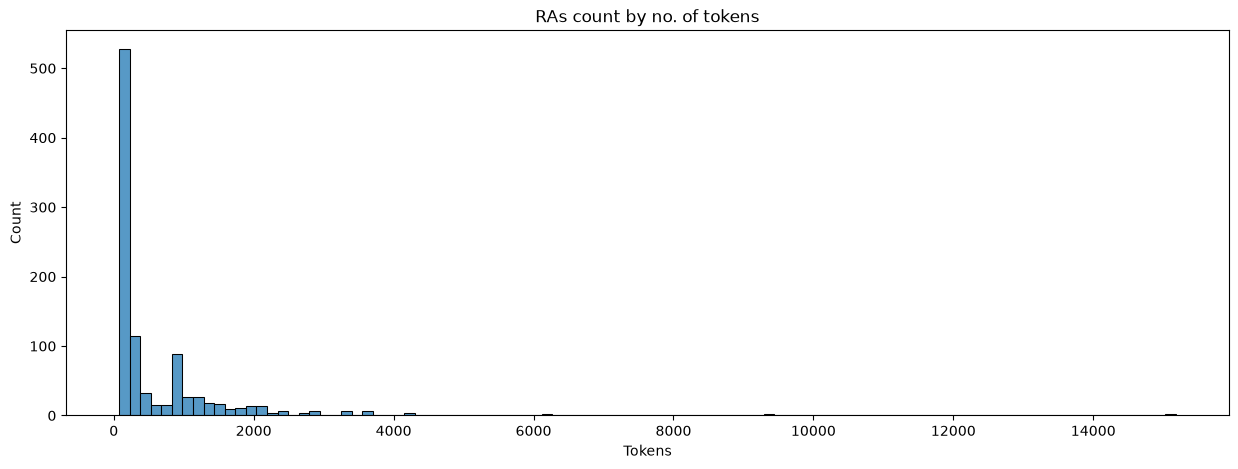

In [ ]:
df.loc[:, 'num_tokens'] = dtm.apply(sum, axis = 1).values
plot_metrics(df, 'num_tokens', title = 'RAs count of no. of tokens', xlabel = 'Tokens')

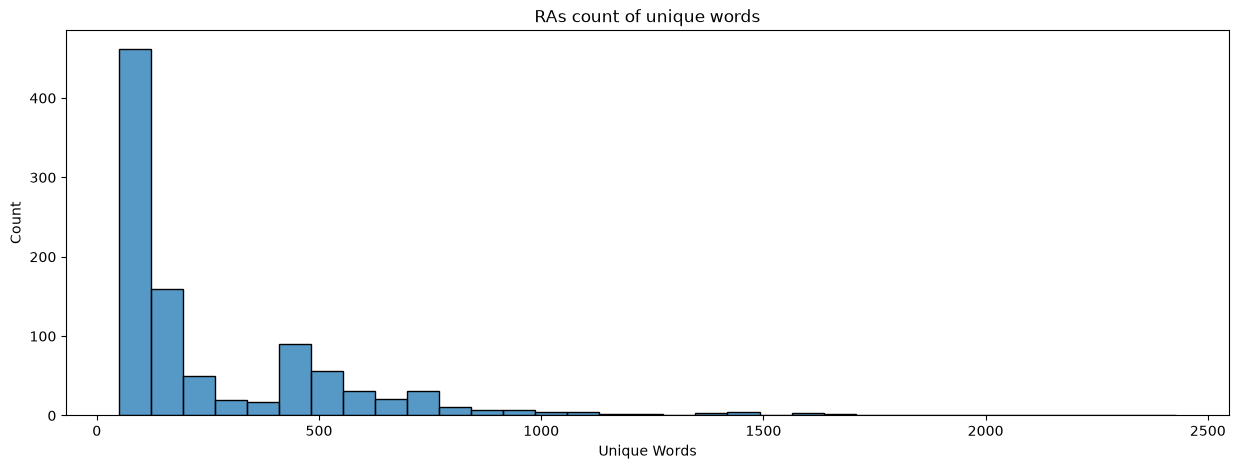

In [ ]:
# unique words, or types, in each text. Types correspond to a text's vocabulary
df.loc[:, 'num_types'] = dtm.apply(np.count_nonzero, axis = 1).values
plot_metrics(df, 'num_types', title = 'RAs count of unique words', xlabel = 'Unique Words')

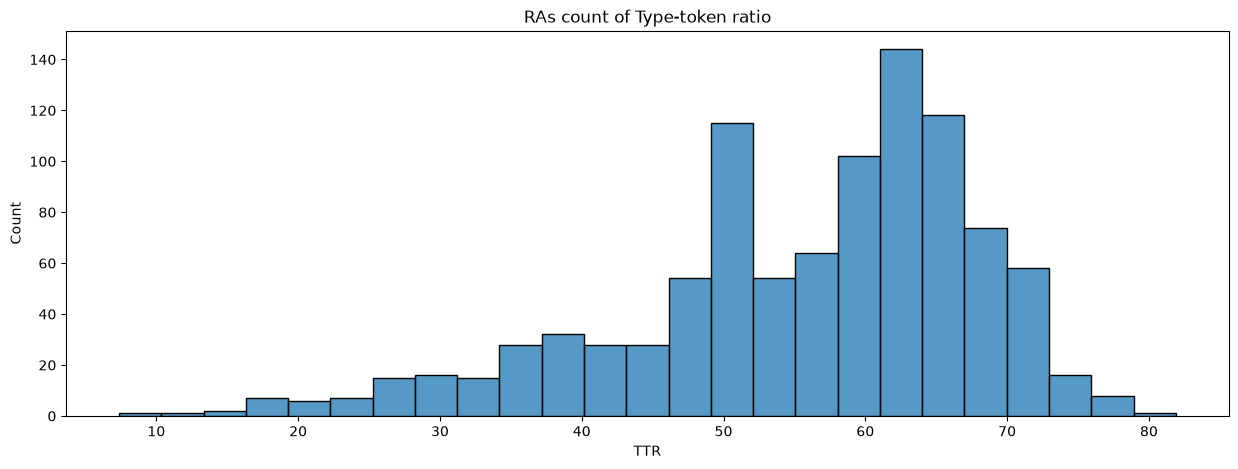

In [ ]:
# lexical diversity - type-token ratio (TTR) measures how much the vocabulary of a text varies over its tokens
# to interpret - a text with a TTR of 100 would never repeat a word
df.loc[:, 'TTR'] = (df['num_types'] / df['num_tokens']) * 100
plot_metrics(df, 'TTR', title = 'RAs count of Type-token ratio', xlabel = 'TTR')

In [ ]:
# low-med-high summary
def show_examples(data, metric, labels = ['low', 'medium', 'high']):
    cuts = pd.qcut(data[metric], len(labels), labels = labels)
    for label in labels:
        idxes = cuts[cuts==label].index
        ex = data[data.index.isin(idxes)].sample()
        print(f"+ {label}: {ex['basename'].item()} ({ex[metric].item():0.2f})")

for metric in ('num_tokens', 'num_types', 'TTR'):
    print("Examples for", metric)
    show_examples(df, metric)
    print("\n")

Examples for num_tokens
+ low: ra_11430_2019 (111.00)
+ medium: ra_11922_2022 (229.00)
+ high: ra_11686_2022 (1545.00)


Examples for num_types
+ low: ra_11022_2018 (94.00)
+ medium: ra_11306_2019 (101.00)
+ high: ra_11319_2019 (428.00)


Examples for TTR
+ low: ra_11579_2021 (51.01)
+ medium: ra_11111_2018 (51.64)
+ high: ra_11191_2019 (64.57)




In [34]:
summed = pd.DataFrame(dtm.sum(), columns = ('count', ))
summed.sort_values('count', ascending = False, inplace = True)
summed.head(5)

,count
provide,7174
philippine,5936
house,5794
service,4861
public,4621


In [35]:
summed.tail(5)

,count
zerp,1
abasig,1
abano,1
abangan,1
aajb,1


In [36]:
# hapax legomena (Greek for 'only said once')
hapaxes = summed[summed['count'] == 1]
print(f"{len(hapaxes)} hapaxes ({len(hapaxes) / len(dtm.T) * 100:0.2f}%)")

4882 hapaxes (32.95%)


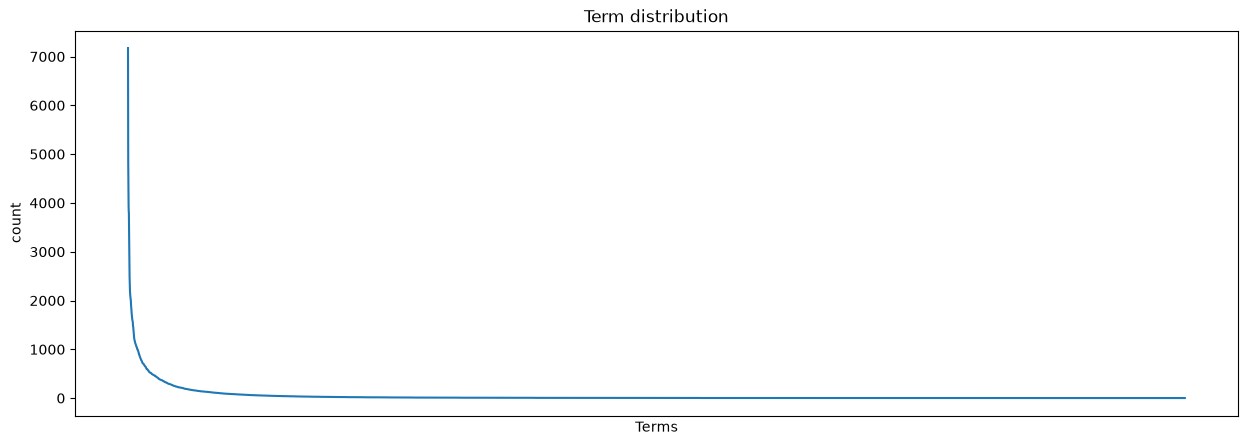

In [ ]:
fig, ax = plt.subplots(figsize = (15, 5))
g = sns.lineplot(x = summed.index, y = 'count', data = summed)
g.set(title = 'Term distribution', xlabel = 'Terms', xticks = [])

# still a lot of terms with high-frequency

In [39]:
tfidf_vectorizer = TfidfVectorizer()
vectorized_tfidf = tfidf_vectorizer.fit_transform(corpus)
tfidf = pd.DataFrame(
    vectorized_tfidf.toarray(),
    columns = tfidf_vectorizer.get_feature_names_out(),
    index = df['basename']
)

In [43]:
def counts_vs_tfidf(dtm, tfidf, idx, n_terms = 10):
    """Compare raw document counts with tf-idf scores."""
    c = dtm.loc[idx].nlargest(n_terms)
    t = tfidf.loc[idx].nlargest(n_terms)
    df = pd.DataFrame({
        'count_term': c.index, 'count': c.values,
        'tfidf_term': t.index, 'tfidf': t.values
    })

    return df

for name in df['basename'].sample(3):
    comparison = counts_vs_tfidf(dtm, tfidf, name)
    print("Republic Act:", name)
    display(comparison)

Republic Act: ra_11430_2019


,count_term,count,tfidf_term,tfidf
0,district,5,tanauan,0.579500
1,house,5,batangas,0.438978
2,office,5,district,0.332889
3,batangas,4,rd,0.249443
4,city,4,lto,0.247603
5,regular,4,office,0.208761
6,tanauan,4,transportation,0.207523
7,general,3,city,0.154713
8,lto,3,land,0.116795
9,philippine,3,house,0.115102


Republic Act: ra_11532_2021


,count_term,count,tfidf_term,tfidf
0,camalig,6,camalig,0.677581
1,high,5,ilawod,0.564650
2,house,5,albay,0.241074
3,ilawod,5,school,0.186814
4,national,5,high,0.150280
5,school,5,national,0.127650
6,albay,3,barangay,0.108458
7,barangay,3,name,0.090395
8,municipality,3,municipality,0.084488
9,philippine,3,house,0.078319


Republic Act: ra_11493_2020


,count_term,count,tfidf_term,tfidf
0,franchise,30,grantee,0.461107
1,grantee,30,franchise,0.439113
2,public,21,ntc,0.237263
3,ntc,15,station,0.215463
4,provide,15,public,0.204289
5,station,15,broadcasting,0.156997
6,facility,10,broadcast,0.136690
7,grant,10,television,0.134008
8,operation,10,provide,0.129780
9,broadcasting,9,radio,0.123249


In [44]:
ra_11493_2020 = counts_vs_tfidf(dtm, tfidf, 'ra_11493_2020', 15)
ra_11493_2020.loc[:, 'corpus_count'] = dtm[ra_11493_2020['count_term']].mean().values
ra_11493_2020.loc[:, 'corpus_tfidf'] = tfidf[ra_11493_2020['tfidf_term']].mean().values

cols = ['count_term', 'count', 'corpus_count', 'tfidf_term', 'tfidf', 'corpus_tfidf']
ra_11493_2020 = ra_11493_2020[cols]
ra_11493_2020

,count_term,count,corpus_count,tfidf_term,tfidf,corpus_tfidf
0,franchise,30,3.838028,grantee,0.461107,0.067211
1,grantee,30,4.517103,franchise,0.439113,0.055112
2,public,21,4.648893,ntc,0.237263,0.023189
3,ntc,15,1.450704,station,0.215463,0.030495
4,provide,15,7.217304,public,0.204289,0.035704
5,station,15,2.110664,broadcasting,0.156997,0.013252
6,facility,10,2.370221,broadcast,0.136690,0.011738
7,grant,10,2.113682,television,0.134008,0.010838
8,operation,10,2.191147,provide,0.129780,0.033736
9,broadcasting,9,0.692153,radio,0.123249,0.012733


In [45]:
tfidf.to_csv('tfidf_scores.csv')